# 05 - SegFormer-B0 : End-to-End Training and Evaluation

Semantic segmentation of substation equipment on the **15-class ground-truth dataset**
(Gomes, 2023), this time with a **SegFormer-B0** model (a hierarchical Transformer
encoder - the *MiT-B0* backbone - paired with a lightweight all-MLP decoder) instead of
the U-Net (notebook `03`) and DeepLabV3+ (notebook `04`) convolutional decoders.

SegFormer's MiT encoder produces multi-scale features through efficient self-attention,
and its simple MLP decoder fuses them with very few parameters, so SegFormer-B0 is a
strong, extremely compact baseline (~3.7M parameters) - a useful counterpoint to the
heavier CNN decoders.

This notebook is **fully self-contained** - it repeats every step end to end:

1. Install dependencies and set a reproducible seed.
2. **Download** the dataset archive from Zenodo (resumable, checksum-verified).
3. **Extract** it and locate the `images/` and `15_masks/` folders.
4. Build class/colour lookups and a PyTorch dataset (colour mask -> class-index map).
5. Reproducible **70 / 15 / 15** train / validation / test split.
6. Train **SegFormer-B0** (`segmentation-models-pytorch`, `mit_b0` ImageNet-pretrained
   encoder) with a combined Dice + Cross-Entropy loss and mixed-precision training.
7. Plot training curves, evaluate on the held-out test set, and report per-class IoU,
   **both the all-class and foreground-only mean IoU**, Dice, and pixel accuracy.
8. Visualise qualitative predictions.

> Runs in Google Colab (GPU recommended) and locally. The dataset, **split (70/15/15),
> seed, input size, loss, and metrics are identical to notebooks `03`/`04`**, so the three
> models are evaluated on the same held-out images. The one deliberate difference is the
> optimiser: SegFormer is a Transformer and trains stably with **AdamW at a low learning
> rate (6e-5)** rather than the `Adam` / `1e-3` used for the CNN decoders.

## 1. Environment setup

Install the segmentation, augmentation, and download libraries if they are missing.
SegFormer needs **`segmentation-models-pytorch>=0.4.0`** (the release that added the MiT
encoders and the SegFormer decoder).

In [1]:
# Install only what is typically missing. Comment out if already installed.
import importlib, sys

def _smp_has_segformer():
    try:
        import segmentation_models_pytorch as smp
        from packaging.version import parse as vparse
        return hasattr(smp, "Segformer") and vparse(smp.__version__) >= vparse("0.4.0")
    except Exception:
        return False

needed = []
if not _smp_has_segformer():
    needed.append("segmentation-models-pytorch>=0.4.0")

for mod, pkg in [("albumentations", "albumentations==1.4.18"),
                 ("requests", "requests"),
                 ("tqdm", "tqdm")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        needed.append(pkg)

if needed:
    !{sys.executable} -m pip install -q {" ".join(needed)}
    print("Installed:", ", ".join(needed))
else:
    print("All required packages already available.")

Installed: segmentation-models-pytorch>=0.4.0


## 2. Imports, configuration and reproducibility

In [2]:
import os
import random
import json
import time
import hashlib
import zipfile
from pathlib import Path
from zipfile import ZipFile
from dataclasses import dataclass

import numpy as np
import cv2
import requests
from tqdm.auto import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import pandas as pd

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

# OpenCV in worker processes should not grab all threads.
cv2.setNumThreads(0)


@dataclass
class Config:
    # Data
    image_size: int = 512          # square input fed to the network
    val_fraction: float = 0.15     # 70 / 15 / 15 split (train gets the remaining 0.70)
    test_fraction: float = 0.15
    max_samples: int | None = None  # set to e.g. 200 for a quick smoke test; None = full dataset

    # Model  -- SegFormer-B0 = MiT-B0 encoder + all-MLP SegFormer decoder.
    encoder_name: str = "mit_b0"     # MiT-B0 backbone; try "mit_b1"/"mit_b2" for more capacity.
    encoder_weights: str = "imagenet"
    architecture: str = "segformer"

    # Training
    epochs: int = 50
    batch_size: int = 8             # drop to 4 if you hit CUDA out-of-memory with a bigger encoder
    num_workers: int = 2
    learning_rate: float = 6e-5     # AdamW + low LR: the stable recipe for Transformer encoders
    weight_decay: float = 1e-2
    early_stopping_patience: int = 8

    seed: int = 42
    checkpoint_path: str = "best_model_segformer_b0.pth"


cfg = Config()


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(cfg.seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("smp    :", smp.__version__)
print("Device :", DEVICE)
if DEVICE.type == "cuda":
    print("GPU    :", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
smp    : 0.6.0
Device : cuda
GPU    : Tesla T4


## 3. Download the dataset archive

Downloads **`substation-semantic-dataset.zip`** (~1.84 GB) from Zenodo, exactly as
`01_data_preparation.ipynb` does: resumable, and skipped when a verified copy already
exists. Saved to Google Drive in Colab, otherwise to `<repo>/data/raw/`.

In [3]:
DATASET_URL = "https://zenodo.org/records/7884270/files/substation-semantic-dataset.zip?download=1"
DATASET_ARCHIVE_NAME = "substation-semantic-dataset.zip"

# Published on the Zenodo record; used to verify the download.
EXPECTED_SIZE_BYTES = 1_844_470_522
EXPECTED_MD5 = "ca897cb85a3b944af6a1355e83530c32"
CHUNK_SIZE = 1024 * 1024  # 1 MB

try:
    from google.colab import drive  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    download_directory = Path("/content/drive/MyDrive")
else:
    repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    download_directory = repo_root / "data" / "raw"

download_directory.mkdir(parents=True, exist_ok=True)
archive_path = download_directory / DATASET_ARCHIVE_NAME
print("Running in Colab:", IN_COLAB)
print("Archive path    :", archive_path)

Mounted at /content/drive
Running in Colab: True
Archive path    : /content/drive/MyDrive/substation-semantic-dataset.zip


In [4]:
def md5_of_file(file_path, chunk_size=CHUNK_SIZE):
    """Return the MD5 hex digest of a file, reading it in chunks."""
    digest = hashlib.md5()
    with open(file_path, "rb") as file_handle, tqdm(
        total=file_path.stat().st_size, unit="B", unit_scale=True, desc="Verifying MD5"
    ) as progress:
        for chunk in iter(lambda: file_handle.read(chunk_size), b""):
            digest.update(chunk)
            progress.update(len(chunk))
    return digest.hexdigest()


def download_file(url, destination, expected_size=None, chunk_size=CHUNK_SIZE):
    """Stream a file to disk, resuming a partial download when possible."""
    partial_path = destination.with_name(destination.name + ".part")
    resume_from = partial_path.stat().st_size if partial_path.exists() else 0

    if expected_size is not None and resume_from > expected_size:
        partial_path.unlink()
        resume_from = 0

    if expected_size is None or resume_from < expected_size:
        headers = {"Range": f"bytes={resume_from}-"} if resume_from else {}
        with requests.get(url, headers=headers, stream=True, timeout=60) as response:
            response.raise_for_status()
            if resume_from and response.status_code != 206:
                resume_from = 0
            remaining = int(response.headers.get("Content-Length", 0))
            total = resume_from + remaining if remaining else expected_size
            with open(partial_path, "ab" if resume_from else "wb") as file_handle, tqdm(
                total=total, initial=resume_from, unit="B", unit_scale=True, desc=destination.name
            ) as progress:
                for chunk in response.iter_content(chunk_size=chunk_size):
                    file_handle.write(chunk)
                    progress.update(len(chunk))

    partial_path.replace(destination)
    return destination


if archive_path.exists() and archive_path.stat().st_size == EXPECTED_SIZE_BYTES:
    print("Archive already downloaded, skipping:", archive_path)
else:
    if archive_path.exists():
        print("Existing archive has an unexpected size, downloading again.")
        archive_path.unlink()
    download_file(DATASET_URL, archive_path, expected_size=EXPECTED_SIZE_BYTES)
    print("Download complete:", archive_path)

# Verify size + MD5 so a corrupt download fails loudly here rather than mid-training.
actual_size = archive_path.stat().st_size
if actual_size != EXPECTED_SIZE_BYTES:
    raise ValueError(f"Size mismatch: expected {EXPECTED_SIZE_BYTES:,} bytes, got {actual_size:,} bytes")
if not zipfile.is_zipfile(archive_path):
    raise ValueError(f"Not a valid zip archive: {archive_path}")
print(f"Size : {actual_size:,} bytes ({actual_size / 1024**3:.2f} GB) - OK")

Archive already downloaded, skipping: /content/drive/MyDrive/substation-semantic-dataset.zip
Size : 1,844,470,522 bytes (1.72 GB) - OK


## 4. Extract and locate the dataset

Reuses the directory extracted by the EDA notebook if present, otherwise extracts the
archive downloaded above. Set `DATASET_DIR` manually if your data lives elsewhere.

In [5]:
REQUIRED_SUBDIRS = ["images", "labels_json", "15_masks"]


def looks_like_dataset(path: Path) -> bool:
    return path.is_dir() and all((path / sub).is_dir() for sub in REQUIRED_SUBDIRS)


def find_extracted_dir() -> Path | None:
    candidates = [
        Path("/content/substation_semantic_dataset"),
        Path.cwd().parent / "data" / "substation_semantic_dataset",
        Path.cwd() / "data" / "substation_semantic_dataset",
        Path.cwd().parent / "data" / "raw",
        Path.cwd() / "data" / "raw",
    ]
    for candidate in candidates:
        if looks_like_dataset(candidate):
            return candidate
        if candidate.is_dir():
            for child in candidate.iterdir():
                if looks_like_dataset(child):
                    return child
    return None


DATASET_DIR = find_extracted_dir()

if DATASET_DIR is None:
    # archive_path was defined in the download cell above.
    target = Path("/content/substation_semantic_dataset") if IN_COLAB else (archive_path.parent / "substation_semantic_dataset")
    print(f"Extracting {archive_path} -> {target} ...")
    target.mkdir(parents=True, exist_ok=True)
    with ZipFile(archive_path) as zf:
        zf.extractall(target)
    DATASET_DIR = target if looks_like_dataset(target) else find_extracted_dir()

if DATASET_DIR is None or not looks_like_dataset(DATASET_DIR):
    raise FileNotFoundError("Dataset directory is missing the expected subfolders.")

IMAGE_DIR = DATASET_DIR / "images"
MASK_DIR = DATASET_DIR / "15_masks"   # 15 equipment classes + Background
print("Dataset directory:", DATASET_DIR)
print("Images           :", IMAGE_DIR)
print("Masks (15-class) :", MASK_DIR)

Extracting /content/drive/MyDrive/substation-semantic-dataset.zip -> /content/substation_semantic_dataset ...
Dataset directory: /content/substation_semantic_dataset
Images           : /content/substation_semantic_dataset/images
Masks (15-class) : /content/substation_semantic_dataset/15_masks


## 5. Classes and colour palette

`classes.txt` lists 16 names: `Background` plus 15 equipment classes. The masks are
colour-coded PNGs. The original authors swap channels before saving, so OpenCV
(`cv2.imread`, which returns BGR) reads back the **reversed** author RGB palette. We build
a colour->class-index lookup to turn each colour mask into an integer label map.

In [6]:
# Author RGB palette, in class-index order (from the dataset's json2png.py / EDA notebook).
AUTHOR_PALETTE_RGB = [
    (0, 0, 0),        # 0  Background
    (162, 0, 255),    # 1  Open blade disconnect switch
    (97, 16, 162),    # 2  Closed blade disconnect switch
    (81, 162, 0),     # 3  Open tandem disconnect switch
    (48, 97, 165),    # 4  Closed tandem disconnect switch
    (121, 121, 121),  # 5  Breaker
    (255, 97, 178),   # 6  Fuse disconnect switch
    (154, 32, 121),   # 7  Glass disc insulator
    (255, 255, 125),  # 8  Porcelain pin insulator
    (162, 243, 162),  # 9  Muffle
    (143, 211, 255),  # 10 Lightning arrester
    (40, 0, 186),     # 11 Recloser
    (255, 182, 0),    # 12 Power transformer
    (138, 138, 0),    # 13 Current transformer
    (162, 48, 0),     # 14 Potential transformer
    (162, 0, 96),     # 15 Tripolar disconnect switch
]

FALLBACK_NAMES = [
    "Background", "Open blade disconnect switch", "Closed blade disconnect switch",
    "Open tandem disconnect switch", "Closed tandem disconnect switch", "Breaker",
    "Fuse disconnect switch", "Glass disc insulator", "Porcelain pin insulator",
    "Muffle", "Lightning arrester", "Recloser", "Power transformer",
    "Current transformer", "Potential transformer", "Tripolar disconnect switch",
]

classes_file = DATASET_DIR / "classes.txt"
if classes_file.is_file():
    CLASS_NAMES = [ln.strip() for ln in classes_file.read_text(encoding="utf-8-sig").splitlines() if ln.strip()]
else:
    CLASS_NAMES = FALLBACK_NAMES

assert len(CLASS_NAMES) == len(AUTHOR_PALETTE_RGB), (len(CLASS_NAMES), len(AUTHOR_PALETTE_RGB))
NUM_CLASSES = len(CLASS_NAMES)
BACKGROUND_INDEX = 0

# cv2.imread returns BGR; the mask colours equal the reversed author RGB tuples.
PALETTE_BGR = np.array([rgb[::-1] for rgb in AUTHOR_PALETTE_RGB], dtype=np.uint8)
PALETTE_RGB = np.array(AUTHOR_PALETTE_RGB, dtype=np.uint8)


def encode_bgr(arr: np.ndarray) -> np.ndarray:
    v = arr.astype(np.uint32)
    return (v[..., 0] << 16) | (v[..., 1] << 8) | v[..., 2]


_palette_codes = encode_bgr(PALETTE_BGR)
assert len(np.unique(_palette_codes)) == NUM_CLASSES, "Palette has duplicate colours."
_code_to_index = {int(c): i for i, c in enumerate(_palette_codes)}


def color_mask_to_index(mask_bgr: np.ndarray) -> np.ndarray:
    """Convert a BGR colour mask (as read by cv2.imread) to an int class-index map."""
    codes = encode_bgr(mask_bgr)
    index_map = np.zeros(codes.shape, dtype=np.int64)
    for code, class_index in _code_to_index.items():
        index_map[codes == code] = class_index
    return index_map


print(f"{NUM_CLASSES} classes:")
for i, name in enumerate(CLASS_NAMES):
    print(f"  {i:>2}: {name}")

16 classes:
   0: Background
   1: Open blade disconnect switch
   2: Closed blade disconnect switch
   3: Open tandem disconnect switch
   4: Closed tandem disconnect switch
   5: Breaker
   6: Fuse disconnect switch
   7: Glass disc insulator
   8: Porcelain pin insulator
   9: Muffle
  10: Lightning arrester
  11: Recloser
  12: Power transformer
  13: Current transformer
  14: Potential transformer
  15: Tripolar disconnect switch


## 6. Pair files and build the reproducible 70 / 15 / 15 split

Each image is matched to its `15_masks` PNG by filename stem. Images with both parts are
shuffled with a fixed seed and split into **70 % train / 15 % validation / 15 % test** -
identical to notebooks `03`/`04`, so the models are evaluated on the same held-out images.

In [7]:
IMAGE_EXTS = {".jpg", ".jpeg"}

image_paths = sorted(p for p in IMAGE_DIR.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
mask_by_stem = {p.stem: p for p in MASK_DIR.iterdir() if p.is_file() and p.suffix.lower() == ".png"}

pairs = [(img, mask_by_stem[img.stem]) for img in image_paths if img.stem in mask_by_stem]
missing = [img.name for img in image_paths if img.stem not in mask_by_stem]
print(f"Images: {len(image_paths)} | paired with masks: {len(pairs)} | missing masks: {len(missing)}")

rng = random.Random(cfg.seed)
rng.shuffle(pairs)

if cfg.max_samples is not None:
    pairs = pairs[: cfg.max_samples]
    print(f"Subsampled to {len(pairs)} pairs (cfg.max_samples).")

n_total = len(pairs)
n_test = int(round(n_total * cfg.test_fraction))
n_val = int(round(n_total * cfg.val_fraction))
test_pairs = pairs[:n_test]
val_pairs = pairs[n_test:n_test + n_val]
train_pairs = pairs[n_test + n_val:]

print(f"Split (70/15/15)  ->  Train: {len(train_pairs)} | Val: {len(val_pairs)} | Test: {len(test_pairs)}")

Images: 1660 | paired with masks: 1660 | missing masks: 0
Split (70/15/15)  ->  Train: 1162 | Val: 249 | Test: 249


## 7. Dataset, augmentation and dataloaders

The dataset reads the image (BGR->RGB), converts the colour mask to a class-index map, then
applies Albumentations transforms (geometric/photometric augmentation on train only,
resize + ImageNet normalisation on all splits). Masks use nearest-neighbour resizing to
preserve class indices.

In [8]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def build_transforms(train: bool) -> A.Compose:
    if train:
        return A.Compose([
            A.Resize(cfg.image_size, cfg.image_size),
            A.HorizontalFlip(p=0.5),
            A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15,
                               border_mode=cv2.BORDER_CONSTANT, value=0, mask_value=0, p=0.5),
            A.RandomBrightnessContrast(p=0.3),
            A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
            ToTensorV2(),
        ])
    return A.Compose([
        A.Resize(cfg.image_size, cfg.image_size),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])


class SubstationSegmentationDataset(Dataset):
    def __init__(self, pairs, transforms):
        self.pairs = pairs
        self.transforms = transforms

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        image_path, mask_path = self.pairs[idx]
        image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        if image_bgr is None:
            raise RuntimeError(f"Could not read image: {image_path}")
        image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

        mask_bgr = cv2.imread(str(mask_path), cv2.IMREAD_COLOR)
        if mask_bgr is None:
            raise RuntimeError(f"Could not read mask: {mask_path}")
        mask = color_mask_to_index(mask_bgr)

        out = self.transforms(image=image, mask=mask)
        image_t = out["image"]
        mask_t = out["mask"].long()
        return image_t, mask_t


train_ds = SubstationSegmentationDataset(train_pairs, build_transforms(train=True))
val_ds = SubstationSegmentationDataset(val_pairs, build_transforms(train=False))
test_ds = SubstationSegmentationDataset(test_pairs, build_transforms(train=False))

pin = DEVICE.type == "cuda"
train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True,
                          num_workers=cfg.num_workers, pin_memory=pin, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=cfg.batch_size, shuffle=False,
                        num_workers=cfg.num_workers, pin_memory=pin)
test_loader = DataLoader(test_ds, batch_size=cfg.batch_size, shuffle=False,
                         num_workers=cfg.num_workers, pin_memory=pin)

print("Batches  ->  train:", len(train_loader), "| val:", len(val_loader), "| test:", len(test_loader))

Batches  ->  train: 145 | val: 32 | test: 32


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_593/1003748549.py:10: UserWarning: Argument(s) 'value, mask_value' are not valid for transform ShiftScaleRotate
  A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15,


### Sanity check: visualise a training sample

Un-normalise one image and overlay its colour-coded ground-truth mask.

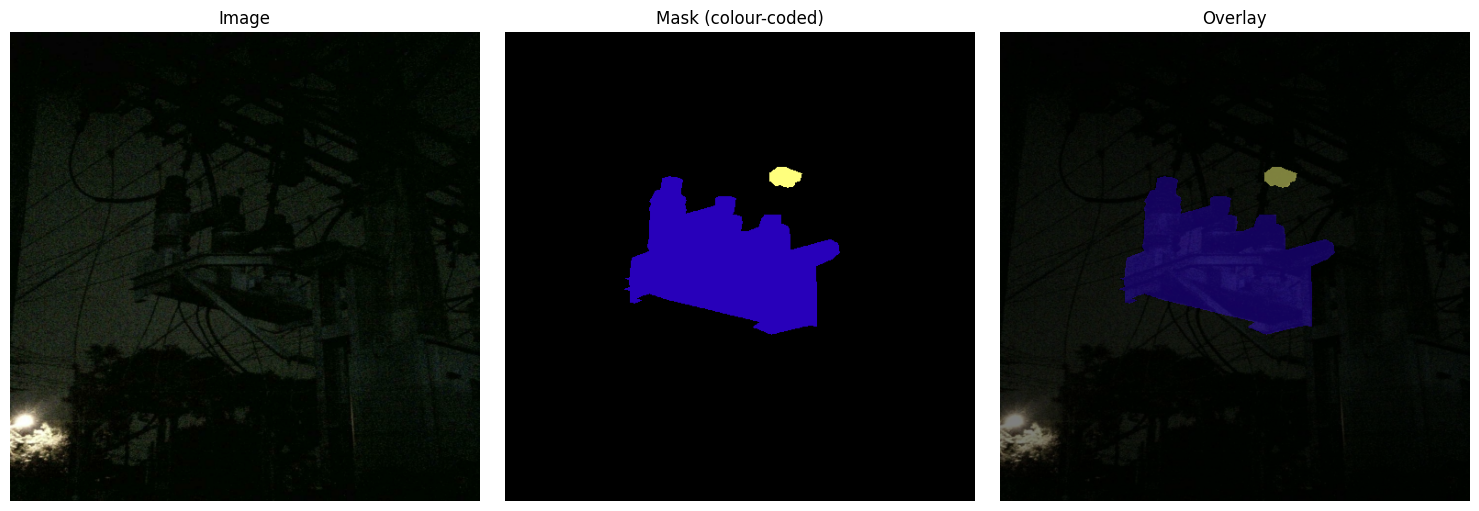

Classes present in this sample: ['Background', 'Porcelain pin insulator', 'Recloser']


In [9]:
def denormalize(image_t: torch.Tensor) -> np.ndarray:
    img = image_t.permute(1, 2, 0).cpu().numpy()
    img = img * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(img, 0, 1)


def index_to_rgb(index_map: np.ndarray) -> np.ndarray:
    return PALETTE_RGB[index_map]


img_t, mask_t = train_ds[0]
img_np = denormalize(img_t)
mask_np = mask_t.cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_np); axes[0].set_title("Image"); axes[0].axis("off")
axes[1].imshow(index_to_rgb(mask_np)); axes[1].set_title("Mask (colour-coded)"); axes[1].axis("off")
axes[2].imshow(img_np); axes[2].imshow(index_to_rgb(mask_np), alpha=0.5)
axes[2].set_title("Overlay"); axes[2].axis("off")
plt.tight_layout(); plt.show()

present = np.unique(mask_np)
print("Classes present in this sample:", [CLASS_NAMES[i] for i in present])

## 8. Model, loss and optimiser

**SegFormer-B0** = the `mit_b0` (MiT-B0) ImageNet-pretrained hierarchical Transformer
encoder plus SegFormer's lightweight all-MLP decoder, from `segmentation-models-pytorch`.
The loss combines **Dice** (robust to the strong class imbalance) and **Cross-Entropy** -
identical to notebooks `03`/`04`.

The optimiser is the one deliberate difference from the CNN notebooks: Transformers are
sensitive to large learning rates, so we use **AdamW (lr 6e-5, weight decay 1e-2)** with a
cosine schedule - the standard, stable SegFormer fine-tuning recipe - instead of
`Adam` / `1e-3`.

In [10]:
def build_model(cfg: Config) -> nn.Module:
    arch = cfg.architecture.lower()
    common = dict(encoder_name=cfg.encoder_name, encoder_weights=cfg.encoder_weights,
                  in_channels=3, classes=NUM_CLASSES)
    if arch == "segformer":
        return smp.Segformer(**common)
    if arch in ("deeplabv3plus", "deeplabv3+"):
        return smp.DeepLabV3Plus(**common)
    if arch == "deeplabv3":
        return smp.DeepLabV3(**common)
    if arch == "unet":
        return smp.Unet(**common)
    if arch == "unetpp":
        return smp.UnetPlusPlus(**common)
    raise ValueError(f"Unknown architecture: {cfg.architecture}")


model = build_model(cfg).to(DEVICE)

dice_loss = smp.losses.DiceLoss(mode="multiclass")
ce_loss = nn.CrossEntropyLoss()


def criterion(logits, targets):
    return dice_loss(logits, targets) + ce_loss(logits, targets)


optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.learning_rate, weight_decay=cfg.weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.epochs)
scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")

n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"{cfg.architecture} / {cfg.encoder_name}: {n_params:.1f}M parameters, {NUM_CLASSES} output classes.")

config.json:   0%|          | 0.00/135 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

segformer / mit_b0: 3.7M parameters, 16 output classes.


## 9. Metrics

We accumulate per-class true-positive / false-positive / false-negative pixel counts across
a whole split with `smp.metrics`, then derive per-class IoU, mean IoU, mean Dice, and pixel
accuracy. Classes absent from a split are excluded from the macro averages.

Because **Background** dominates the pixels and scores very high, we report **two** mean
IoUs: the all-class mean, and a **foreground-only mean IoU** (Background excluded). The
foreground number is the honest measure of equipment-segmentation quality and is the one
to compare across models.

In [11]:
class SegMetrics:
    """Accumulate per-class TP/FP/FN over an epoch and compute IoU / Dice / accuracy."""

    def __init__(self, num_classes: int, background_index: int = 0):
        self.num_classes = num_classes
        self.background_index = background_index
        self.reset()

    def reset(self):
        self.tp = torch.zeros(self.num_classes, dtype=torch.long)
        self.fp = torch.zeros(self.num_classes, dtype=torch.long)
        self.fn = torch.zeros(self.num_classes, dtype=torch.long)
        self.tn = torch.zeros(self.num_classes, dtype=torch.long)

    @torch.no_grad()
    def update(self, preds: torch.Tensor, targets: torch.Tensor):
        tp, fp, fn, tn = smp.metrics.get_stats(
            preds, targets, mode="multiclass", num_classes=self.num_classes
        )
        self.tp += tp.sum(0).cpu()
        self.fp += fp.sum(0).cpu()
        self.fn += fn.sum(0).cpu()
        self.tn += tn.sum(0).cpu()

    def per_class_iou(self):
        denom = (self.tp + self.fp + self.fn).float()
        return torch.where(denom > 0, self.tp.float() / denom, torch.full_like(denom, float("nan")))

    def per_class_dice(self):
        denom = (2 * self.tp + self.fp + self.fn).float()
        return torch.where(denom > 0, 2 * self.tp.float() / denom, torch.full_like(denom, float("nan")))

    def summary(self):
        iou = self.per_class_iou()
        dice = self.per_class_dice()

        # Foreground-only view: drop the background class before averaging.
        fg = torch.ones(self.num_classes, dtype=torch.bool)
        fg[self.background_index] = False
        iou_fg = iou[fg]
        dice_fg = dice[fg]

        total = (self.tp + self.fn).sum().float()
        pixel_acc = (self.tp.sum().float() / total).item() if total > 0 else float("nan")
        return {
            "mean_iou": torch.nanmean(iou).item(),
            "mean_iou_fg": torch.nanmean(iou_fg).item(),
            "mean_dice": torch.nanmean(dice).item(),
            "mean_dice_fg": torch.nanmean(dice_fg).item(),
            "pixel_acc": pixel_acc,
        }

## 10. Training loop

Mixed-precision training, validation after each epoch, best-checkpoint saving on validation
mean IoU, and early stopping. Checkpoints track the **foreground** mean IoU too so you can
see progress on the classes that matter.

In [12]:
def run_epoch(loader, train: bool):
    model.train(train)
    metrics = SegMetrics(NUM_CLASSES, background_index=BACKGROUND_INDEX)
    running_loss = 0.0
    n_batches = 0

    for images, masks in loader:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.set_grad_enabled(train):
            with torch.amp.autocast("cuda", enabled=DEVICE.type == "cuda"):
                logits = model(images)
                loss = criterion(logits, masks)

            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        preds = logits.argmax(dim=1)
        metrics.update(preds.detach(), masks.detach())
        running_loss += loss.item()
        n_batches += 1

    stats = metrics.summary()
    stats["loss"] = running_loss / max(n_batches, 1)
    return stats, metrics


history = {"train_loss": [], "val_loss": [], "train_miou": [], "val_miou": [],
           "train_miou_fg": [], "val_miou_fg": []}
best_val_miou = -1.0
epochs_without_improvement = 0

for epoch in range(1, cfg.epochs + 1):
    t0 = time.time()
    train_stats, _ = run_epoch(train_loader, train=True)
    val_stats, _ = run_epoch(val_loader, train=False)
    scheduler.step()

    history["train_loss"].append(train_stats["loss"])
    history["val_loss"].append(val_stats["loss"])
    history["train_miou"].append(train_stats["mean_iou"])
    history["val_miou"].append(val_stats["mean_iou"])
    history["train_miou_fg"].append(train_stats["mean_iou_fg"])
    history["val_miou_fg"].append(val_stats["mean_iou_fg"])

    improved = val_stats["mean_iou"] > best_val_miou
    if improved:
        best_val_miou = val_stats["mean_iou"]
        epochs_without_improvement = 0
        torch.save({"model_state": model.state_dict(),
                    "config": cfg.__dict__,
                    "class_names": CLASS_NAMES,
                    "val_miou": best_val_miou,
                    "val_miou_fg": val_stats["mean_iou_fg"],
                    "epoch": epoch}, cfg.checkpoint_path)
    else:
        epochs_without_improvement += 1

    print(f"Epoch {epoch:02d}/{cfg.epochs} "
          f"| train loss {train_stats['loss']:.4f} mIoU {train_stats['mean_iou']:.4f} "
          f"(fg {train_stats['mean_iou_fg']:.4f}) "
          f"| val loss {val_stats['loss']:.4f} mIoU {val_stats['mean_iou']:.4f} "
          f"(fg {val_stats['mean_iou_fg']:.4f}) "
          f"| {time.time() - t0:.0f}s {'* best' if improved else ''}")

    if epochs_without_improvement >= cfg.early_stopping_patience:
        print(f"Early stopping: no val mIoU improvement for {cfg.early_stopping_patience} epochs.")
        break

print(f"\nBest validation mean IoU: {best_val_miou:.4f} (saved to {cfg.checkpoint_path})")

Epoch 01/50 | train loss 2.3544 mIoU 0.0836 (fg 0.0384) | val loss 1.4864 mIoU 0.1159 (fg 0.0624) | 221s * best
Epoch 02/50 | train loss 1.4277 mIoU 0.1305 (fg 0.0777) | val loss 1.1751 mIoU 0.1497 (fg 0.0977) | 209s * best
Epoch 03/50 | train loss 1.1652 mIoU 0.1556 (fg 0.1035) | val loss 1.0331 mIoU 0.1778 (fg 0.1271) | 209s * best
Epoch 04/50 | train loss 1.0534 mIoU 0.1761 (fg 0.1250) | val loss 0.9422 mIoU 0.1999 (fg 0.1504) | 211s * best
Epoch 05/50 | train loss 0.9521 mIoU 0.1988 (fg 0.1490) | val loss 0.8938 mIoU 0.2175 (fg 0.1690) | 210s * best
Epoch 06/50 | train loss 0.9062 mIoU 0.2152 (fg 0.1664) | val loss 0.8283 mIoU 0.2360 (fg 0.1887) | 209s * best
Epoch 07/50 | train loss 0.8453 mIoU 0.2355 (fg 0.1879) | val loss 0.7996 mIoU 0.2710 (fg 0.2260) | 209s * best
Epoch 08/50 | train loss 0.8079 mIoU 0.2690 (fg 0.2235) | val loss 0.7666 mIoU 0.3001 (fg 0.2570) | 212s * best
Epoch 09/50 | train loss 0.7821 mIoU 0.2886 (fg 0.2443) | val loss 0.7101 mIoU 0.3231 (fg 0.2812) | 207s

## 11. Training curves

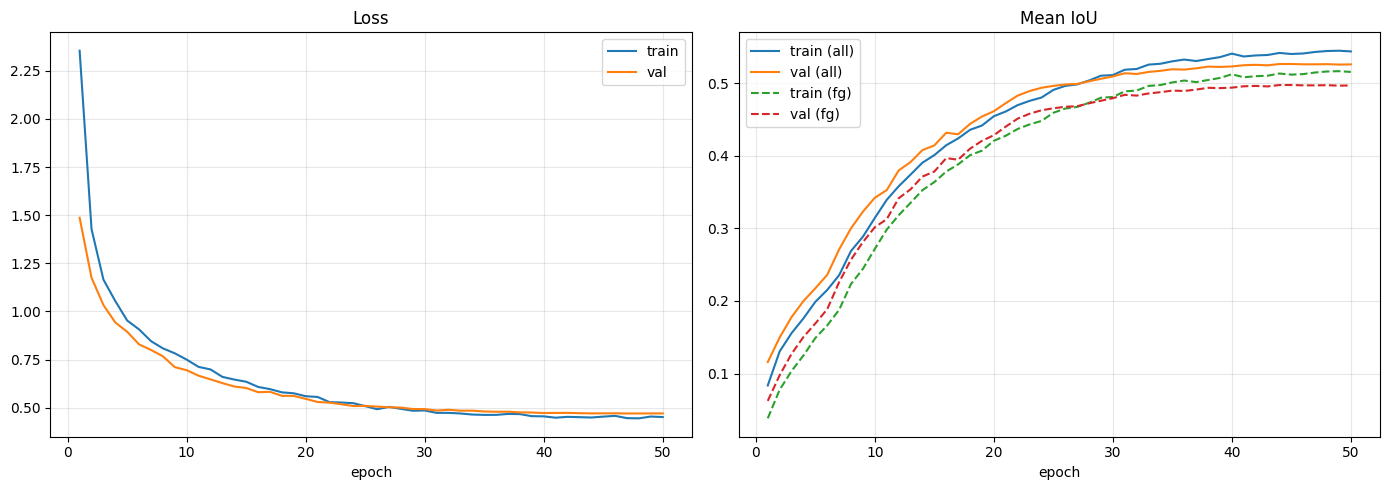

In [13]:
epochs_ran = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(epochs_ran, history["train_loss"], label="train")
axes[0].plot(epochs_ran, history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(epochs_ran, history["train_miou"], label="train (all)")
axes[1].plot(epochs_ran, history["val_miou"], label="val (all)")
axes[1].plot(epochs_ran, history["train_miou_fg"], "--", label="train (fg)")
axes[1].plot(epochs_ran, history["val_miou_fg"], "--", label="val (fg)")
axes[1].set_title("Mean IoU"); axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 12. Evaluation on the held-out test set

Reload the best checkpoint and compute overall metrics (all-class and foreground-only)
plus a per-class IoU / Dice table.

In [14]:
checkpoint = torch.load(cfg.checkpoint_path, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state"])
model.eval()
print(f"Loaded best checkpoint from epoch {checkpoint['epoch']} (val mIoU {checkpoint['val_miou']:.4f}).")

test_metrics = SegMetrics(NUM_CLASSES, background_index=BACKGROUND_INDEX)
with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        with torch.amp.autocast("cuda", enabled=DEVICE.type == "cuda"):
            logits = model(images)
        preds = logits.argmax(dim=1)
        test_metrics.update(preds, masks)

summary = test_metrics.summary()
print("\nTest set results")
print(f"  Mean IoU  (all 16)      : {summary['mean_iou']:.4f}")
print(f"  Mean IoU  (foreground)  : {summary['mean_iou_fg']:.4f}   <- compare models on this")
print(f"  Mean Dice (all 16)      : {summary['mean_dice']:.4f}")
print(f"  Mean Dice (foreground)  : {summary['mean_dice_fg']:.4f}")
print(f"  Pixel accuracy          : {summary['pixel_acc']:.4f}")

Loaded best checkpoint from epoch 45 (val mIoU 0.5263).

Test set results
  Mean IoU  (all 16)      : 0.5037
  Mean IoU  (foreground)  : 0.4730   <- compare models on this
  Mean Dice (all 16)      : 0.6506
  Mean Dice (foreground)  : 0.6285
  Pixel accuracy          : 0.9637


In [15]:
iou = test_metrics.per_class_iou().numpy()
dice = test_metrics.per_class_dice().numpy()
support = (test_metrics.tp + test_metrics.fn).numpy()  # ground-truth pixels per class

per_class_df = pd.DataFrame({
    "class": CLASS_NAMES,
    "IoU": iou,
    "Dice": dice,
    "GT_pixels": support,
})
per_class_df = per_class_df.sort_values("IoU", ascending=False, na_position="last").reset_index(drop=True)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(per_class_df.to_string(index=False))

                          class    IoU   Dice  GT_pixels
                     Background 0.9632 0.9813   60036955
                        Breaker 0.7767 0.8743     397010
              Power transformer 0.7687 0.8693    1530792
                       Recloser 0.6933 0.8189    1302530
 Closed blade disconnect switch 0.5304 0.6932     743455
     Tripolar disconnect switch 0.4808 0.6494     173524
          Potential transformer 0.4781 0.6469      45757
         Fuse disconnect switch 0.4538 0.6243      49092
            Current transformer 0.4420 0.6130     145323
        Porcelain pin insulator 0.4251 0.5965     425159
           Glass disc insulator 0.4006 0.5720      76528
Closed tandem disconnect switch 0.3939 0.5652     120072
                         Muffle 0.3395 0.5069      66307
  Open tandem disconnect switch 0.3327 0.4993     102302
   Open blade disconnect switch 0.2917 0.4517      12937
             Lightning arrester 0.2878 0.4470      46113


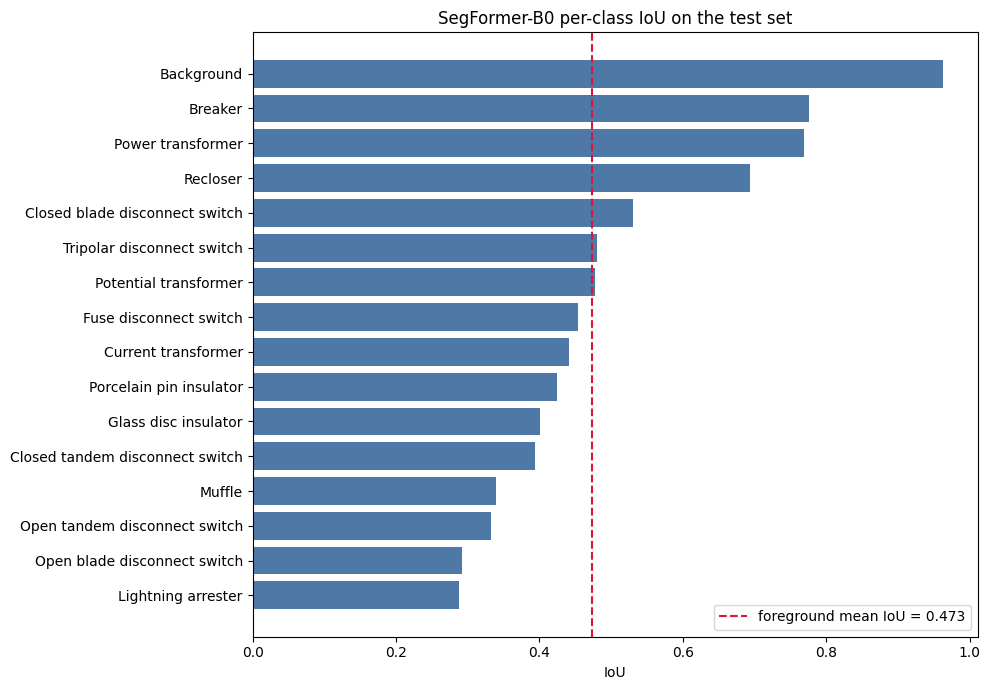

In [16]:
# Per-class IoU bar chart (classes present in the test set).
plot_df = per_class_df.dropna(subset=["IoU"]).sort_values("IoU")
plt.figure(figsize=(10, 7))
plt.barh(plot_df["class"], plot_df["IoU"], color="#4E79A7")
plt.axvline(summary["mean_iou_fg"], color="crimson", linestyle="--",
            label=f"foreground mean IoU = {summary['mean_iou_fg']:.3f}")
plt.xlabel("IoU"); plt.title("SegFormer-B0 per-class IoU on the test set"); plt.legend()
plt.tight_layout(); plt.show()

## 13. Qualitative predictions

Overlay predictions against ground truth for a few test images.

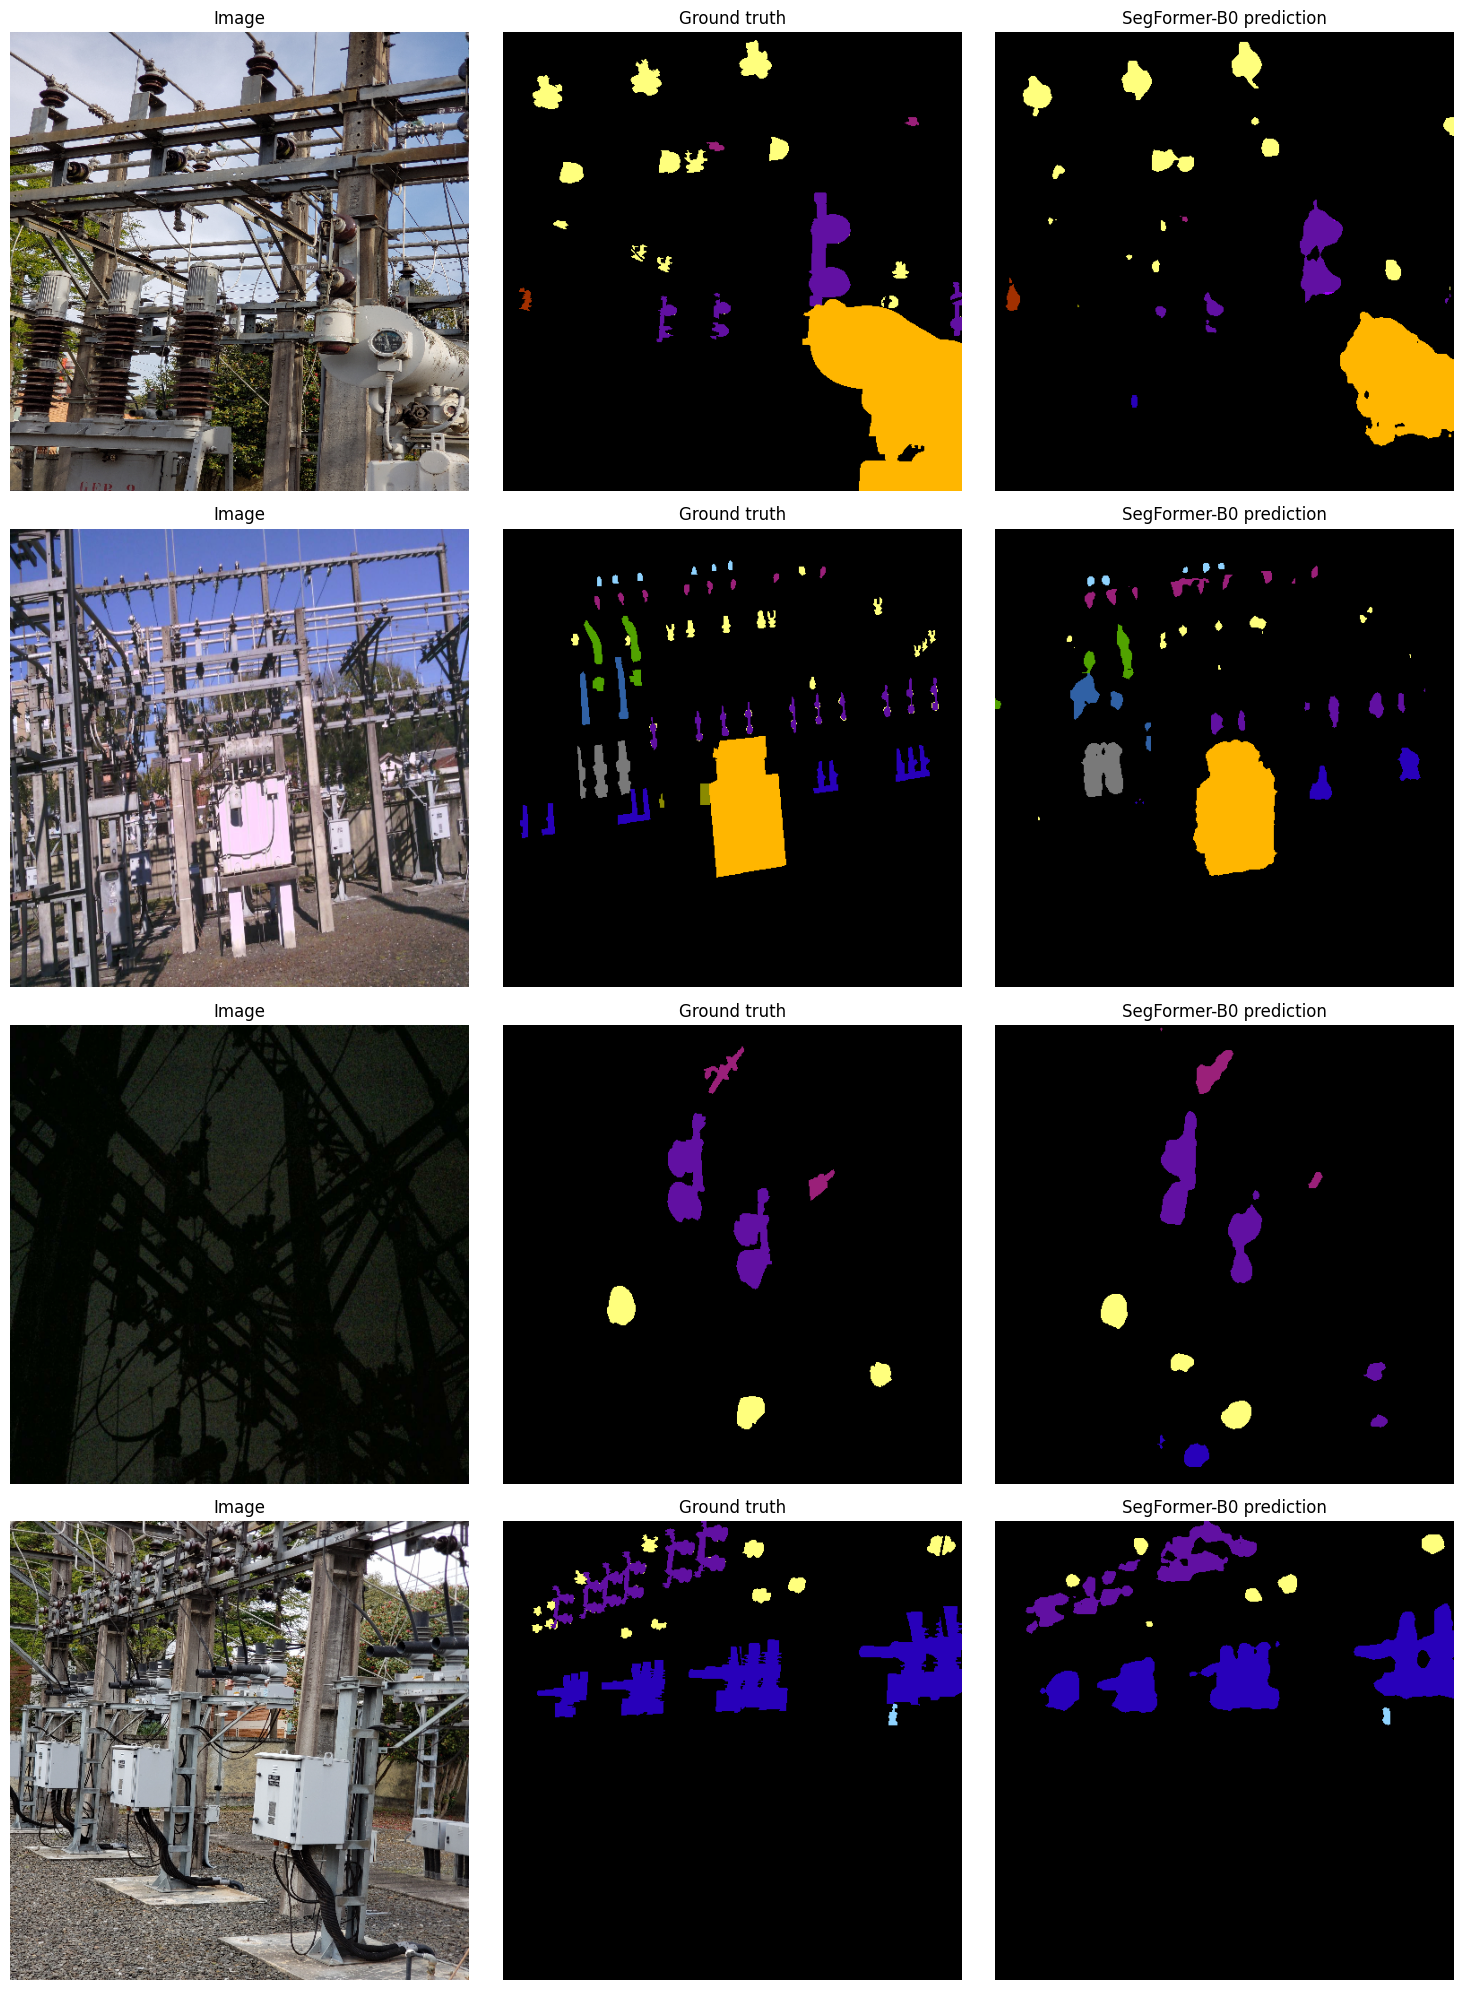

In [17]:
def predict_batch(images):
    with torch.no_grad():
        with torch.amp.autocast("cuda", enabled=DEVICE.type == "cuda"):
            logits = model(images.to(DEVICE))
        return logits.argmax(dim=1).cpu().numpy()


n_show = min(4, len(test_ds))
fig, axes = plt.subplots(n_show, 3, figsize=(15, 5 * n_show))
if n_show == 1:
    axes = axes[None, :]

for row in range(n_show):
    img_t, mask_t = test_ds[row]
    pred = predict_batch(img_t.unsqueeze(0))[0]
    img_np = denormalize(img_t)

    axes[row, 0].imshow(img_np); axes[row, 0].set_title("Image"); axes[row, 0].axis("off")
    axes[row, 1].imshow(index_to_rgb(mask_t.numpy())); axes[row, 1].set_title("Ground truth"); axes[row, 1].axis("off")
    axes[row, 2].imshow(index_to_rgb(pred)); axes[row, 2].set_title("SegFormer-B0 prediction"); axes[row, 2].axis("off")

plt.tight_layout(); plt.show()

## 14. Save artefacts and summary

The best model weights are already in `best_model_segformer_b0.pth`. Save the metrics and
a per-class IoU table alongside it, under SegFormer-specific filenames so they do not
overwrite the notebook `03` (U-Net) or `04` (DeepLabV3+) results.

In [18]:
results = {
    "architecture": cfg.architecture,
    "encoder": cfg.encoder_name,
    "num_classes": NUM_CLASSES,
    "test_mean_iou": summary["mean_iou"],
    "test_mean_iou_foreground": summary["mean_iou_fg"],
    "test_mean_dice": summary["mean_dice"],
    "test_mean_dice_foreground": summary["mean_dice_fg"],
    "test_pixel_accuracy": summary["pixel_acc"],
    "best_val_mean_iou": best_val_miou,
    "per_class_iou": {CLASS_NAMES[i]: (None if np.isnan(iou[i]) else float(iou[i])) for i in range(NUM_CLASSES)},
}
with open("test_results_segformer_b0.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

print("Saved:")
print("  best_model_segformer_b0.pth    - best model weights + config")
print("  test_results_segformer_b0.json - test metrics and per-class IoU")
print(f"\nFinal test mean IoU (all): {summary['mean_iou']:.4f} | "
      f"foreground: {summary['mean_iou_fg']:.4f} | "
      f"Dice: {summary['mean_dice']:.4f} | pixel acc: {summary['pixel_acc']:.4f}")

Saved:
  best_model_segformer_b0.pth    - best model weights + config
  test_results_segformer_b0.json - test metrics and per-class IoU

Final test mean IoU (all): 0.5037 | foreground: 0.4730 | Dice: 0.6506 | pixel acc: 0.9637


## Notes and next steps

- **Comparing against notebooks `03` (U-Net) and `04` (DeepLabV3+).** The dataset, 70/15/15
  split, seed, input size, loss, and metrics are identical, so the three models are scored
  on the same held-out images. Tabulate each notebook's `test_results_*.json` (compare on
  the **foreground** mean IoU) alongside parameter count and inference speed - SegFormer-B0
  is by far the smallest model (~3.7M params), so even comparable accuracy is a strong result.
- **Optimiser.** SegFormer is a Transformer and diverges easily under the CNN notebooks'
  `Adam` / `1e-3`; we use `AdamW` / `6e-5` with cosine annealing. If training is still noisy,
  add a short linear warmup or lower the LR to `3e-5`.
- **Bigger backbone.** Set `cfg.encoder_name = "mit_b1"` or `"mit_b2"` (and drop
  `cfg.batch_size` to 4) for more capacity; B2 is usually the best accuracy/size trade-off
  on datasets this small.
- **Class imbalance** still caps the rare switch classes. Combine with a class-weighted /
  Focal / Tversky loss or oversampling of rare-class images for further gains.
- **Resolution.** 512x512 is a speed/accuracy compromise; larger inputs or tiling help thin
  objects (insulators, arresters).
- **Quick smoke test.** Set `cfg.max_samples = 200` and `cfg.epochs = 3` to validate the
  full pipeline end to end before a long run.